# PRACTICAL 5
# CONTENT-BASED RECOMMENDER SYSTEM
# Dataset: MovieLens 10M
# Uses: movies.dat, ratings.dat, tags.dat


In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer

# SETTINGS

In [ ]:
DATA_FOLDER = "/content/drive/MyDrive/Content/RS/ML_10M"

In [6]:
MOVIES_FILE = os.path.join(DATA_FOLDER, "movies.dat")
RATINGS_FILE = os.path.join(DATA_FOLDER, "ratings.dat")
TAGS_FILE = os.path.join(DATA_FOLDER, "tags.dat")

In [7]:
TOP_N = 10
RANKING_K = 10
RELEVANCE_THRESHOLD = 4.0

In [38]:
DEMO_MOVIE_ID = 1
DEMO_USER_ID = 892

In [9]:
TFIDF_MIN_DF = 2

In [35]:
# Ranking evaluation on all MovieLens 10M users is slow for a
# classroom practical. Set this to None to evaluate all users.
MAX_EVAL_USERS = 500
EVAL_RANDOM_STATE = 42

# 1. CHECK FILES

In [10]:
for path in [MOVIES_FILE, RATINGS_FILE, TAGS_FILE]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")

print("Dataset folder:", DATA_FOLDER)

Dataset folder: /content/drive/MyDrive/Classes/MCA3/RS/ML_10M


# 2. LOAD MOVIELENS 10M

* movies.dat:
  - MovieID::Title::Genres

* ratings.dat:
  - UserID::MovieID::Rating::Timestamp

* tags.dat:
  - UserID::MovieID::Tag::Timestamp


In [11]:
movies = pd.read_csv(
    MOVIES_FILE,
    sep="::",
    engine="python",
    names=["movieId", "title", "genres"],
    encoding="latin-1"
)

ratings = pd.read_csv(
    RATINGS_FILE,
    sep="::",
    engine="python",
    names=["userId", "movieId", "rating", "timestamp"],
    encoding="latin-1"
)

tags = pd.read_csv(
    TAGS_FILE,
    sep="::",
    engine="python",
    names=["userId", "movieId", "tag", "timestamp"],
    encoding="latin-1"
)

print("\nMovies :", movies.shape)
print("Ratings:", ratings.shape)
print("Tags   :", tags.shape)

print("\nMovies sample")
display(movies.head())

print("\nRatings sample")
display(ratings.head())

print("\nTags sample")
display(tags.head())

print("\nUnique users :", ratings["userId"].nunique())
print("Unique movies:", ratings["movieId"].nunique())
print("Total ratings:", len(ratings))
print("Total tags   :", len(tags))


Movies : (10681, 3)
Ratings: (10000054, 4)
Tags   : (95580, 4)

Movies sample


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy



Ratings sample


,userId,movieId,rating,timestamp
0,1,122,5.0,838985046
1,1,185,5.0,838983525
2,1,231,5.0,838983392
3,1,292,5.0,838983421
4,1,316,5.0,838983392



Tags sample


,userId,movieId,tag,timestamp
0,15,4973,excellent!,1215184630
1,20,1747,politics,1188263867
2,20,1747,satire,1188263867
3,20,2424,chick flick 212,1188263835
4,20,2424,hanks,1188263835



Unique users : 69878
Unique movies: 10677
Total ratings: 10000054
Total tags   : 95580


# 3. GENRE FREQUENCY VISUALIZATION

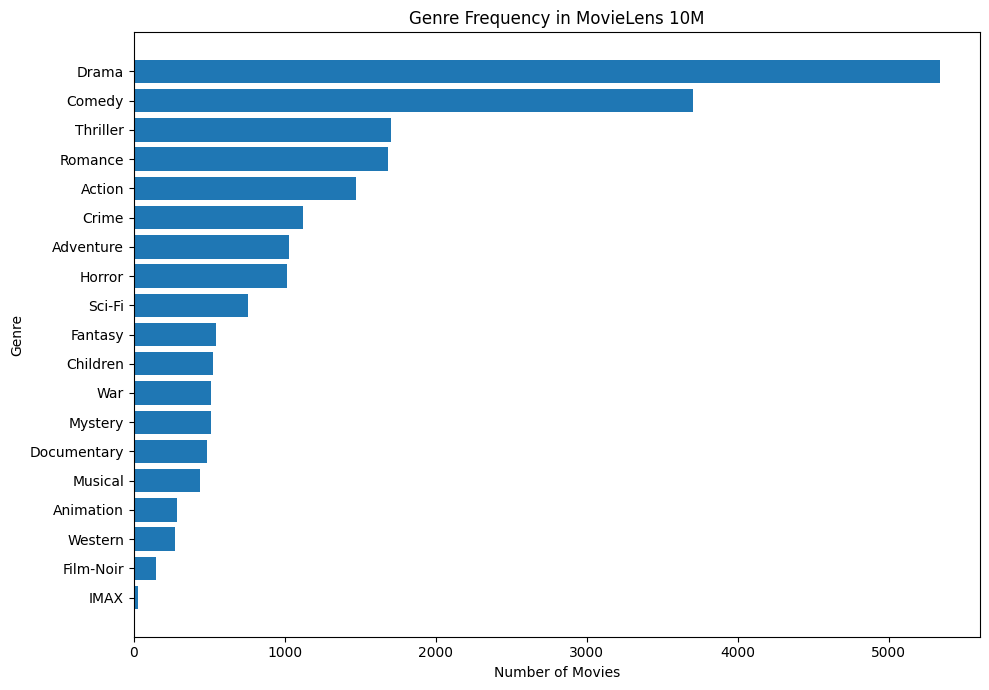

In [12]:
genre_counts = (
    movies["genres"]
    .fillna("")
    .str.split("|")
    .explode()
)

genre_counts = genre_counts[
    genre_counts != "(no genres listed)"
]

genre_counts = genre_counts.value_counts().sort_values()

plt.figure(figsize=(10, 7))
plt.barh(genre_counts.index, genre_counts.values)
plt.xlabel("Number of Movies")
plt.ylabel("Genre")
plt.title("Genre Frequency in MovieLens 10M")
plt.tight_layout()
plt.show()


# 4. PREPARE GENRES


In [13]:
movies["genre_text"] = (
    movies["genres"]
    .fillna("")
    .replace("(no genres listed)", "", regex=False)
    .str.replace("|", " ", regex=False)
    .str.lower()
)

# 5. CLEAN AND AGGREGATE TAGS

In [14]:
tags["tag"] = (
    tags["tag"]
    .fillna("")
    .astype(str)
    .str.lower()
    .str.strip()
)

tags_clean = tags[tags["tag"] != ""].copy()

# Keep the same tag only once per movie.
tags_clean = tags_clean.drop_duplicates(
    subset=["movieId", "tag"]
)

movie_tags = (
    tags_clean
    .groupby("movieId")["tag"]
    .agg(" ".join)
    .rename("tag_text")
    .reset_index()
)

print("\nAggregated tags")
display(movie_tags.head())


Aggregated tags


,movieId,tag_text
0,1,pixar animation animated fun toy toys rated-g ...
1,2,for children game animals joe johnston robin w...
2,3,funniest movies comedinha de velhinhos engraã...
3,4,girl movie
4,5,steve martin pregnancy remake family wedding f...


# 6. COMBINE GENRES AND TAGS

In [15]:
movie_content = movies.merge(
    movie_tags,
    on="movieId",
    how="left"
)

movie_content["tag_text"] = movie_content["tag_text"].fillna("")

movie_content["content"] = (
    movie_content["genre_text"]
    + " "
    + movie_content["tag_text"]
)

movie_content["content"] = (
    movie_content["content"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("\nCombined movie content")
display(
    movie_content[
        ["movieId", "title", "genres", "tag_text", "content"]
    ].head(10)
)


Combined movie content


,movieId,title,genres,tag_text,content
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,pixar animation animated fun toy toys rated-g ...,adventure animation children comedy fantasy pi...
1,2,Jumanji (1995),Adventure|Children|Fantasy,for children game animals joe johnston robin w...,adventure children fantasy for children game a...
2,3,Grumpier Old Men (1995),Comedy|Romance,funniest movies comedinha de velhinhos engraã...,comedy romance funniest movies comedinha de ve...
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,girl movie,comedy drama romance girl movie
4,5,Father of the Bride Part II (1995),Comedy,steve martin pregnancy remake family wedding f...,comedy steve martin pregnancy remake family we...
5,6,Heat (1995),Action|Crime|Thriller,can't remember setting:la who cares dvds overr...,action crime thriller can't remember setting:l...
6,7,Sabrina (1995),Comedy|Romance,based on a play greg kinnear remake relationsh...,comedy romance based on a play greg kinnear re...
7,8,Tom and Huck (1995),Adventure|Children,adapted from:book author:mark twain,adventure children adapted from:book author:ma...
8,9,Sudden Death (1995),Action,can't remember jean-claude van damme,action can't remember jean-claude van damme
9,10,GoldenEye (1995),Action|Adventure|Thriller,franchise bond seen more than once sean bean d...,action adventure thriller franchise bond seen ...



# 7. TF-IDF ITEM FEATURES


In [16]:
tfidf = TfidfVectorizer(
    stop_words="english",
    min_df=TFIDF_MIN_DF,
    lowercase=True
)

item_features = tfidf.fit_transform(
    movie_content["content"]
)

feature_names = tfidf.get_feature_names_out()

print("\nTF-IDF matrix shape:", item_features.shape)
print("Number of content features:", len(feature_names))


TF-IDF matrix shape: (10681, 6251)
Number of content features: 6251


# 8. MOVIE ID MAPPING

In [17]:
movie_ids = movie_content["movieId"].to_numpy()

movie_to_row = {
    movie_id: row
    for row, movie_id in enumerate(movie_ids)
}

# 9. MANUAL COSINE SIMILARITY

In [18]:
def manual_cosine_scores(query_vector, candidate_matrix):
    """
    Compare one sparse query vector with every row in a sparse
    candidate matrix.

    cosine(A,B) = (A.B) / (||A|| ||B||)
    """

    query_vector = csr_matrix(query_vector)
    candidate_matrix = csr_matrix(candidate_matrix)

    dot_products = (
        candidate_matrix @ query_vector.T
    ).toarray().ravel()

    query_norm = np.sqrt(
        query_vector.multiply(query_vector).sum()
    )

    candidate_norms = np.sqrt(
        candidate_matrix
        .multiply(candidate_matrix)
        .sum(axis=1)
    ).A1

    denominators = candidate_norms * query_norm

    scores = np.divide(
        dot_products,
        denominators,
        out=np.zeros_like(dot_products, dtype=float),
        where=denominators > 0
    )

    return scores

# 10. FIND CONTENT-SIMILAR MOVIES

In [19]:
def similar_movies(movie_id, top_n=TOP_N):

    if movie_id not in movie_to_row:
        return pd.DataFrame()

    target_row = movie_to_row[movie_id]

    scores = manual_cosine_scores(
        item_features[target_row],
        item_features
    )

    scores[target_row] = -np.inf

    candidate_rows = np.where(np.isfinite(scores))[0]

    if len(candidate_rows) == 0:
        return pd.DataFrame()

    n_keep = min(top_n, len(candidate_rows))

    candidate_scores = scores[candidate_rows]

    top_local = np.argpartition(
        candidate_scores,
        -n_keep
    )[-n_keep:]

    top_rows = candidate_rows[top_local]

    top_rows = top_rows[
        np.argsort(scores[top_rows])[::-1]
    ]

    result = movie_content.iloc[top_rows][
        ["movieId", "title", "genres", "tag_text"]
    ].copy()

    result["Cosine Similarity"] = scores[top_rows]

    return result.reset_index(drop=True)

# 11. DEMONSTRATE ITEM-TO-ITEM SIMILARITY

In [20]:
similar_demo = similar_movies(
    DEMO_MOVIE_ID,
    top_n=TOP_N
)

if DEMO_MOVIE_ID in movie_to_row:
    target_title = movie_content.iloc[
        movie_to_row[DEMO_MOVIE_ID]
    ]["title"]
else:
    target_title = str(DEMO_MOVIE_ID)

print("\nTarget movie:", target_title)
display(similar_demo)


Target movie: Toy Story (1995)


,movieId,title,genres,tag_text,Cosine Similarity
0,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,toys pixar disney tom hanks sequel imdb top 25...,0.633774
1,1920,Small Soldiers (1998),Animation|Children|Fantasy|War,seen at the cinema toys,0.404195
2,6377,Finding Nemo (2003),Adventure|Animation|Children|Comedy,talking animals pixar animation dvd disney fis...,0.376247
3,3759,Fun and Fancy Free (1947),Animation|Children|Musical,disney animation erlend's dvds,0.363680
4,3615,Dinosaur (2000),Animation|Children,disney animated feature computer animation dis...,0.360169
5,2566,Doug's 1st Movie (1999),Animation|Children,disney,0.351068
6,2355,"Bug's Life, A (1998)",Adventure|Animation|Children|Comedy,talking animals kid flick pixar acting circus ...,0.348056
7,32153,Once Upon a Forest (1993),Adventure|Animation|Children|Fantasy,,0.346051
8,63859,Bolt (2008),Action|Adventure|Animation|Children|Comedy,below r,0.343869
9,4886,"Monsters, Inc. (2001)",Animation|Children|Comedy|Fantasy,good cartoon children pixar dvd seen more than...,0.337631


# 12. PLOT TOP-N SIMILAR MOVIES

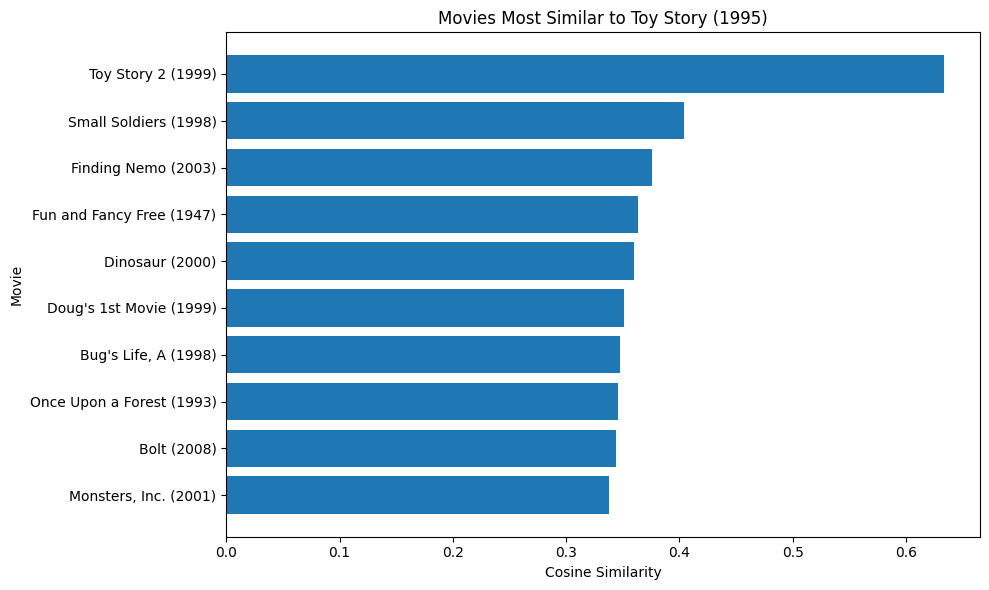

In [21]:
if not similar_demo.empty:

    plot_data = similar_demo.sort_values(
        "Cosine Similarity",
        ascending=True
    )

    plt.figure(figsize=(10, 6))

    plt.barh(
        plot_data["title"],
        plot_data["Cosine Similarity"]
    )

    plt.xlabel("Cosine Similarity")
    plt.ylabel("Movie")
    plt.title(f"Movies Most Similar to {target_title}")

    plt.tight_layout()
    plt.show()

# 13. COSINE-SIMILARITY DISTRIBUTION


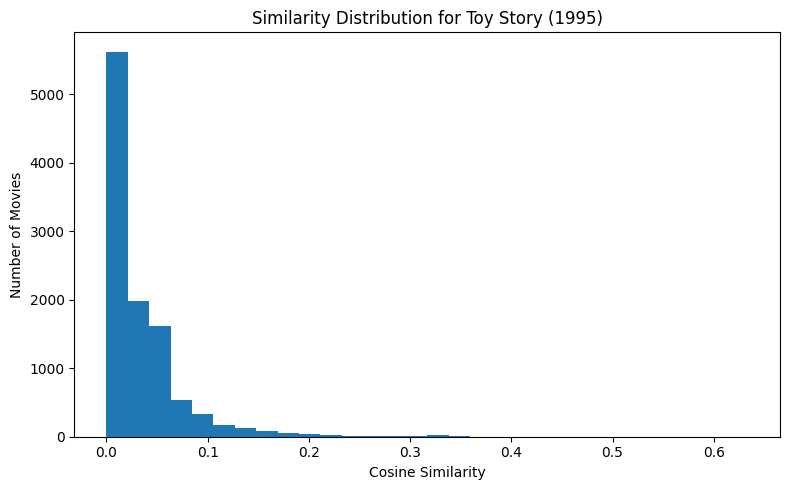

In [22]:
if DEMO_MOVIE_ID in movie_to_row:

    demo_row = movie_to_row[DEMO_MOVIE_ID]

    demo_scores = manual_cosine_scores(
        item_features[demo_row],
        item_features
    )

    demo_scores = np.delete(
        demo_scores,
        demo_row
    )

    plt.figure(figsize=(8, 5))
    plt.hist(demo_scores, bins=30)

    plt.xlabel("Cosine Similarity")
    plt.ylabel("Number of Movies")
    plt.title(f"Similarity Distribution for {target_title}")

    plt.tight_layout()
    plt.show()

# 14. CHRONOLOGICAL TRAIN-TEST SPLIT

* Latest rating for every user -> test
* Earlier ratings              -> training

In [39]:
test_indices = (
    ratings
    .groupby("userId")["timestamp"]
    .idxmax()
)

is_test = ratings.index.isin(test_indices)

test_data = ratings.loc[is_test].copy()
train_data = ratings.loc[~is_test].copy()

print("\nTraining interactions:", len(train_data))
print("Testing interactions :", len(test_data))

train_by_user = train_data.groupby(
    "userId",
    sort=False
)


Training interactions: 9930176
Testing interactions : 69878


# 15. BUILD A RATING-WEIGHTED USER PROFILE

In [40]:
def build_user_profile(user_id):
    """
    Build one user's content profile.

    user_mean:
        Mean rating in the user's training history.

    weights:
        max(rating - user_mean, 0)

    profile:
        Weighted average of the content vectors of movies that
        contributed positively to the user's preferences.
    """

    if user_id not in train_by_user.groups:
        return None, pd.DataFrame(), np.nan

    history = train_by_user.get_group(user_id).copy()

    history = history[
        history["movieId"].isin(movie_to_row)
    ].copy()

    if history.empty:
        return None, history, np.nan

    user_mean = history["rating"].mean()

    weights = np.maximum(
        history["rating"].to_numpy(dtype=float)
        - user_mean,
        0.0
    )

    # Fallback if all ratings are identical.
    if weights.sum() == 0:
        weights = (
            history["rating"]
            .to_numpy(dtype=float)
            / 5.0
        )

    positions = np.array(
        [
            movie_to_row[movie_id]
            for movie_id in history["movieId"]
        ],
        dtype=int
    )

    user_items = item_features[positions]

    weighted_items = user_items.multiply(
        weights[:, None]
    )

    profile = weighted_items.sum(axis=0)
    profile = csr_matrix(profile)

    profile = profile / (
        weights.sum() + 1e-12
    )

    return profile, history, user_mean

# 16. SHOW STRONGEST USER-PROFILE FEATURES

In [41]:
def top_user_features(user_profile, top_n=15):

    if user_profile is None:
        return pd.DataFrame()

    values = user_profile.toarray().ravel()

    positive_positions = np.where(
        values > 0
    )[0]

    if len(positive_positions) == 0:
        return pd.DataFrame()

    n_keep = min(top_n, len(positive_positions))

    local_values = values[positive_positions]

    top_local = np.argpartition(
        local_values,
        -n_keep
    )[-n_keep:]

    top_positions = positive_positions[top_local]

    top_positions = top_positions[
        np.argsort(values[top_positions])[::-1]
    ]

    return pd.DataFrame({
        "Feature": feature_names[top_positions],
        "Profile Weight": values[top_positions]
    })

# 17. PERSONALIZED TOP-N RECOMMENDATION

In [42]:
def recommend_movies(user_id, top_n=TOP_N):

    profile, history, user_mean = build_user_profile(
        user_id
    )

    if profile is None:
        return pd.DataFrame()

    scores = manual_cosine_scores(
        profile,
        item_features
    )

    seen_rows = [
        movie_to_row[movie_id]
        for movie_id in history["movieId"]
        if movie_id in movie_to_row
    ]

    scores[seen_rows] = -np.inf

    candidate_rows = np.where(
        np.isfinite(scores)
    )[0]

    if len(candidate_rows) == 0:
        return pd.DataFrame()

    n_keep = min(top_n, len(candidate_rows))

    candidate_scores = scores[candidate_rows]

    top_local = np.argpartition(
        candidate_scores,
        -n_keep
    )[-n_keep:]

    top_rows = candidate_rows[top_local]

    top_rows = top_rows[
        np.argsort(scores[top_rows])[::-1]
    ]

    result = movie_content.iloc[top_rows][
        ["movieId", "title", "genres", "tag_text"]
    ].copy()

    result["Content Similarity"] = scores[top_rows]

    return result.reset_index(drop=True)

# 18. EXPLAIN A RECOMMENDATION

In [43]:
def explain_recommendation(
    user_profile,
    movie_id,
    top_n=5
):

    if (
        user_profile is None
        or movie_id not in movie_to_row
    ):
        return pd.DataFrame()

    movie_vector = item_features[
        movie_to_row[movie_id]
    ]

    contribution = (
        movie_vector
        .multiply(user_profile)
        .toarray()
        .ravel()
    )

    positive_positions = np.where(
        contribution > 0
    )[0]

    if len(positive_positions) == 0:
        return pd.DataFrame()

    n_keep = min(
        top_n,
        len(positive_positions)
    )

    values = contribution[positive_positions]

    top_local = np.argpartition(
        values,
        -n_keep
    )[-n_keep:]

    top_positions = positive_positions[top_local]

    top_positions = top_positions[
        np.argsort(
            contribution[top_positions]
        )[::-1]
    ]

    return pd.DataFrame({
        "Matching Feature": feature_names[top_positions],
        "Contribution": contribution[top_positions]
    })

# 19. DEMONSTRATE USER PROFILE

In [44]:
demo_profile, demo_history, demo_user_mean = (
    build_user_profile(DEMO_USER_ID)
)

print("\nUser:", DEMO_USER_ID)
print("Training ratings:", len(demo_history))

if pd.notna(demo_user_mean):
    print("Mean training rating:", round(demo_user_mean, 3))

demo_features = top_user_features(
    demo_profile,
    top_n=15
)

print("\nStrongest user-profile features")
display(demo_features)


User: 892
Training ratings: 160
Mean training rating: 3.888

Strongest user-profile features


,Feature,Profile Weight
0,best,0.098591
1,oscar,0.069894
2,afi,0.064443
3,100,0.049763
4,dvds,0.046134
5,movie,0.041783
6,robert,0.040962
7,seen,0.038555
8,tumey,0.038106
9,crime,0.037841


# 20. PLOT USER PROFILE FEATURES

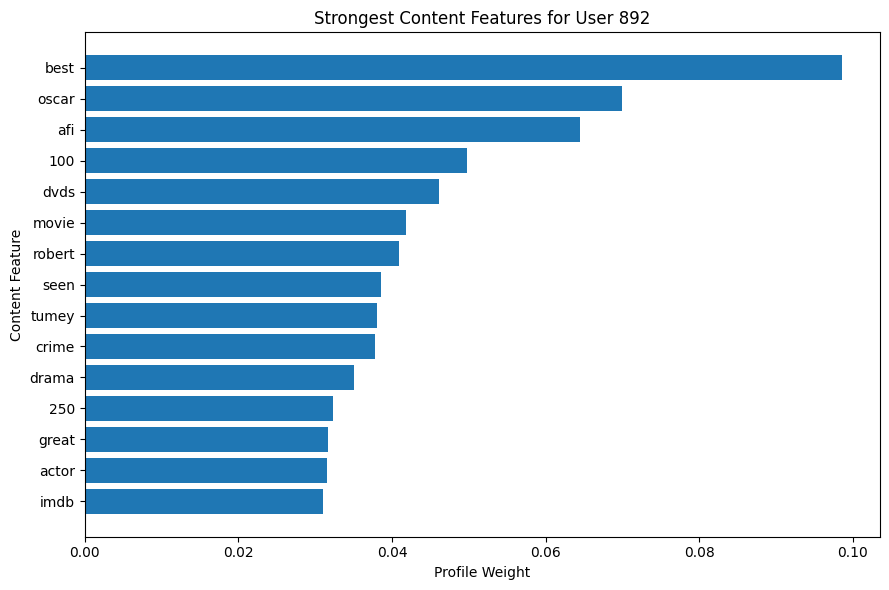

In [45]:
if not demo_features.empty:

    plot_features = demo_features.sort_values(
        "Profile Weight",
        ascending=True
    )

    plt.figure(figsize=(9, 6))

    plt.barh(
        plot_features["Feature"],
        plot_features["Profile Weight"]
    )

    plt.xlabel("Profile Weight")
    plt.ylabel("Content Feature")
    plt.title(
        f"Strongest Content Features for User {DEMO_USER_ID}"
    )

    plt.tight_layout()
    plt.show()

# 21. TOP-N PERSONALIZED RECOMMENDATIONS


In [46]:
recommendations = recommend_movies(
    DEMO_USER_ID,
    top_n=TOP_N
)

print(
    f"\nTOP {TOP_N} CONTENT-BASED "
    f"RECOMMENDATIONS FOR USER {DEMO_USER_ID}"
)

display(recommendations)


TOP 10 CONTENT-BASED RECOMMENDATIONS FOR USER 892


,movieId,title,genres,tag_text,Content Similarity
0,1945,On the Waterfront (1954),Crime|Drama,classic performance boxing coulda been a conte...,0.530795
1,1939,"Best Years of Our Lives, The (1946)",Drama|War,afi 100 national film registry oscar (best act...,0.520384
2,1250,"Bridge on the River Kwai, The (1957)",Adventure|Drama|War,based on a book classic war world war ii pow n...,0.519655
3,1225,Amadeus (1984),Drama,based on a play biography music true story sta...,0.495994
4,1287,Ben-Hur (1959),Action|Adventure|Drama|Romance,national film registry oscar (best actor) osca...,0.487274
5,1953,"French Connection, The (1971)",Action|Crime|Drama|Thriller,cops action hackman mob car chase crime drama ...,0.484830
6,1035,"Sound of Music, The (1965)",Musical|Romance,austria scenic classic good music rogers and h...,0.483824
7,905,It Happened One Night (1934),Comedy|Romance,romantic comedy clark gable screwball national...,0.474018
8,1929,Grand Hotel (1932),Drama,national film registry oscar (best picture) tu...,0.473690
9,1090,Platoon (1986),Drama|War,willem defoe willem dafoe cameo:oliver stone c...,0.473116


# 22. PLOT PERSONALIZED RECOMMENDATIONS

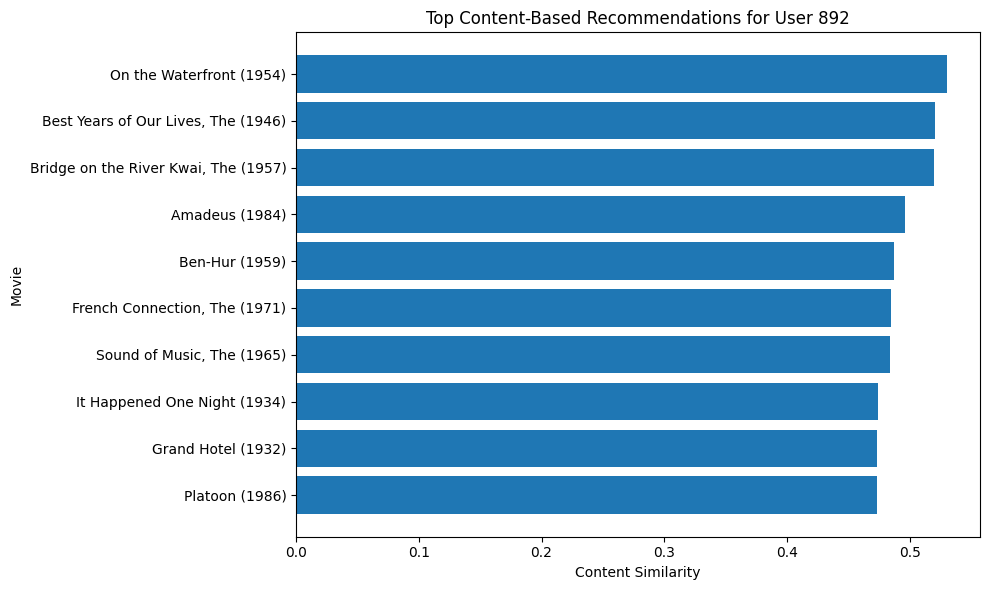

In [47]:
if not recommendations.empty:

    plot_recommendations = recommendations.sort_values(
        "Content Similarity",
        ascending=True
    )

    plt.figure(figsize=(10, 6))

    plt.barh(
        plot_recommendations["title"],
        plot_recommendations["Content Similarity"]
    )

    plt.xlabel("Content Similarity")
    plt.ylabel("Movie")
    plt.title(
        f"Top Content-Based Recommendations "
        f"for User {DEMO_USER_ID}"
    )

    plt.tight_layout()
    plt.show()

# 23. EXPLAIN FIRST RECOMMENDATION

In [48]:
if (
    demo_profile is not None
    and not recommendations.empty
):

    first_movie_id = int(
        recommendations.iloc[0]["movieId"]
    )

    first_movie_title = recommendations.iloc[0]["title"]

    explanation = explain_recommendation(
        demo_profile,
        first_movie_id,
        top_n=8
    )

    print("\nRecommended movie:", first_movie_title)
    print("Strongest matching content features")

    display(explanation)


Recommended movie: On the Waterfront (1954)
Strongest matching content features


,Matching Feature,Contribution
0,best,0.045732
1,oscar,0.024663
2,afi,0.020746
3,100,0.011574
4,picture,0.005026
5,classic,0.004574
6,film,0.003978
7,actor,0.002765



# 24. PREPARE RANKING EVALUATION


In [49]:
eligible_test = test_data[
    test_data["rating"] >= RELEVANCE_THRESHOLD
].copy()

eligible_test = eligible_test[
    eligible_test["movieId"].isin(movie_to_row)
]

eligible_test = eligible_test[
    eligible_test["userId"].isin(train_by_user.groups)
]

if (
    MAX_EVAL_USERS is not None
    and len(eligible_test) > MAX_EVAL_USERS
):
    eligible_test = (
        eligible_test
        .sample(
            n=MAX_EVAL_USERS,
            random_state=EVAL_RANDOM_STATE
        )
        .sort_values("userId")
    )

print(
    "\nUsers selected for ranking evaluation:",
    len(eligible_test)
)


Users selected for ranking evaluation: 500


# 25. HIT RATE, MRR AND NDCG

In [50]:
ranking_rows = []

for number, row in enumerate(
    eligible_test.itertuples(),
    start=1
):

    profile, history, _ = build_user_profile(
        row.userId
    )

    if profile is None:
        continue

    scores = manual_cosine_scores(
        profile,
        item_features
    )

    seen_rows = [
        movie_to_row[movie_id]
        for movie_id in history["movieId"]
        if movie_id in movie_to_row
    ]

    scores[seen_rows] = -np.inf

    target_row = movie_to_row[row.movieId]
    target_score = scores[target_row]

    if not np.isfinite(target_score):
        continue

    # Rank = 1 + number of unseen movies with a larger score.
    rank = int(
        np.sum(scores > target_score)
    ) + 1

    hit = int(rank <= RANKING_K)

    rr = (
        1.0 / rank
        if rank <= RANKING_K
        else 0.0
    )

    ndcg = (
        1.0 / np.log2(rank + 1)
        if rank <= RANKING_K
        else 0.0
    )

    ranking_rows.append({
        "userId": row.userId,
        "movieId": row.movieId,
        "Target Rating": row.rating,
        "Target Rank": rank,
        f"Hit@{RANKING_K}": hit,
        f"RR@{RANKING_K}": rr,
        f"NDCG@{RANKING_K}": ndcg
    })

    if number == 1 or number % 100 == 0:
        print(
            f"Evaluated {number} / "
            f"{len(eligible_test)} users"
        )

ranking_results = pd.DataFrame(ranking_rows)

if len(ranking_results) > 0:

    hit_rate = ranking_results[
        f"Hit@{RANKING_K}"
    ].mean()

    mrr_at_k = ranking_results[
        f"RR@{RANKING_K}"
    ].mean()

    ndcg_at_k = ranking_results[
        f"NDCG@{RANKING_K}"
    ].mean()

else:

    hit_rate = np.nan
    mrr_at_k = np.nan
    ndcg_at_k = np.nan

print("\n" + "=" * 70)
print("CONTENT-BASED RANKING EVALUATION")
print("=" * 70)

print("Evaluated users:", len(ranking_results))
print(f"Hit Rate@{RANKING_K}:", round(hit_rate, 4))
print(f"MRR@{RANKING_K}:", round(mrr_at_k, 4))
print(f"NDCG@{RANKING_K}:", round(ndcg_at_k, 4))

display(ranking_results.head(15))

Evaluated 1 / 500 users
Evaluated 100 / 500 users
Evaluated 200 / 500 users
Evaluated 300 / 500 users
Evaluated 400 / 500 users
Evaluated 500 / 500 users

CONTENT-BASED RANKING EVALUATION
Evaluated users: 500
Hit Rate@10: 0.034
MRR@10: 0.0144
NDCG@10: 0.0188


,userId,movieId,Target Rating,Target Rank,Hit@10,RR@10,NDCG@10
0,141,515,5.0,648,0,0.0,0.0
1,381,230,4.0,3184,0,0.0,0.0
2,410,168,4.0,3888,0,0.0,0.0
3,473,36,5.0,1899,0,0.0,0.0
4,592,2657,4.0,1281,0,0.0,0.0
5,613,1848,4.0,63,0,0.0,0.0
6,881,58,5.0,6056,0,0.0,0.0
7,882,203,4.0,9299,0,0.0,0.0
8,1033,2858,4.0,205,0,0.0,0.0
9,1135,2804,5.0,382,0,0.0,0.0
